# Retail Sales: Exploratory Data Analysis

**Objective:** uncover sales patterns, customer behaviour and actionable business insights from a retail transactions dataset.
**Stack:** Python, pandas, matplotlib, seaborn.

> **Data note.** This notebook follows the schema of the Kaggle *Retail Sales Dataset* (Transaction ID, Date, Customer ID, Gender, Age, Product Category, Quantity, Price per Unit, Total Amount) plus a `Product Name` column so that product-level analysis is possible.
> The bundled file `retail_sales_synthetic.csv` is **synthetic** (1,000 transactions, calendar year 2023) because Kaggle could not be reached while building this. All findings below describe *this* file and are illustrative.
> To run on real data, download a dataset from Kaggle (search "retail sales dataset") and change `DATA_PATH` in the next cell. Every chart recomputes, but the written observations should then be re-read against the new numbers. If the file has no `Product Name` column, the product analysis automatically falls back to `Product Category`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# ---- point this at the real Kaggle CSV (e.g. "retail_sales_dataset.csv") to re-run on real data ----
DATA_PATH = "retail_sales_synthetic.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
BLUE, ORANGE, GREY = "#2f6db5", "#e07b39", "#8a8f98"
CAT_COLORS = {"Electronics": BLUE, "Clothing": ORANGE, "Beauty": "#4aa67a"}
money = mtick.StrMethodFormatter("{x:,.0f}")

df = pd.read_csv(DATA_PATH)

## 1. Initial inspection
Shape, column types, missing values and duplicates, before anything else.

In [2]:
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns\n")
print("Column dtypes and null counts")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum(), "unique": df.nunique()}))
print(f"\nDuplicate rows: {df.duplicated().sum()}  |  Duplicate Transaction IDs: {df['Transaction ID'].duplicated().sum()}")
df.head()

Shape: 1,000 rows x 10 columns

Column dtypes and null counts


,dtype,nulls,unique
Transaction ID,int64,0,1000
Date,str,0,343
Customer ID,str,0,591
Gender,str,0,2
Age,int64,0,47
Product Category,str,0,3
Product Name,str,0,15
Quantity,int64,0,4
Price per Unit,int64,0,5
Total Amount,int64,0,18



Duplicate rows: 0  |  Duplicate Transaction IDs: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price per Unit,Total Amount
0,1,2023-01-02,CUST209,Male,53,Beauty,Perfume,4,50,200
1,2,2023-01-03,CUST185,Female,35,Beauty,Skincare Set,4,300,1200
2,3,2023-01-03,CUST687,Female,55,Beauty,Perfume,3,50,150
3,4,2023-01-04,CUST190,Female,29,Electronics,Wireless Earbuds,3,300,900
4,5,2023-01-04,CUST673,Female,42,Clothing,Sneakers,3,50,150


**Observations**
- 1,000 transactions across 10 columns, with **no missing values and no duplicate rows or transaction IDs**, so no imputation or de-duplication is needed.
- `Date` is stored as text and is converted to a datetime below. Everything else already has a sensible type.
- Consistency check below: `Total Amount` should equal `Quantity x Price per Unit` on every row.

In [3]:
df["Date"] = pd.to_datetime(df["Date"])
mismatch = (df["Quantity"] * df["Price per Unit"] != df["Total Amount"]).sum()
print(f"Rows where Total Amount != Quantity x Price per Unit: {mismatch}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")

# Helper columns used throughout
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")
df["Weekday"] = df["Date"].dt.day_name()
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 64],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-64"])
PRODUCT_COL = "Product Name" if "Product Name" in df.columns else "Product Category"
print("Product column used for product analysis:", PRODUCT_COL)

Rows where Total Amount != Quantity x Price per Unit: 0
Date range: 2023-01-02 to 2023-12-31
Product column used for product analysis: Product Name


The arithmetic check passes, so `Total Amount` is trustworthy as the revenue measure for the rest of the analysis.

## 2. Descriptive statistics
Mean, median, mode and standard deviation for every numerical column (the ID column is excluded because it carries no meaning).

In [4]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
stats = pd.DataFrame({
    "mean": df[num_cols].mean(),
    "median": df[num_cols].median(),
    "mode": df[num_cols].mode().iloc[0],
    "std": df[num_cols].std(),
    "min": df[num_cols].min(),
    "max": df[num_cols].max(),
}).round(2)
stats["mean/median"] = (stats["mean"] / stats["median"]).round(2)
display(stats)
display(df[num_cols].describe().round(2))

,mean,median,mode,std,min,max,mean/median
Age,41.32,41.0,64,12.02,18,64,1.01
Quantity,2.42,2.0,1,1.10,1,4,1.21
Price per Unit,103.31,30.0,25,144.04,25,500,3.44
Total Amount,246.35,100.0,50,396.03,25,2000,2.46


,Age,Quantity,Price per Unit,Total Amount
count,1000.00,1000.00,1000.00,1000.00
mean,41.32,2.42,103.31,246.35
std,12.02,1.10,144.04,396.03
min,18.00,1.00,25.00,25.00
25%,33.00,1.00,25.00,50.00
50%,41.00,2.00,30.00,100.00
75%,50.25,3.00,50.00,200.00
max,64.00,4.00,500.00,2000.00


**Observations**
- **Spend is strongly right-skewed.** The average transaction is about 246 but the median is only 100, and the standard deviation (about 396) is larger than the mean. A minority of high-ticket purchases pull the average up, so the *median* describes the typical basket far better than the mean.
- **`Price per Unit` is skewed in the same way** (median 30 against a mean of about 103), which suggests a catalogue with many cheap items and a few expensive ones. This is confirmed in the product analysis below.
- The **mode of `Age` is 64**, which is the upper bound of the data and not a real concentration of 64-year-olds. Ages are capped at 18-64 in this file, so the mean and median are more informative than the mode here.
- Quantity is spread fairly evenly from 1 to 4 items, so basket *size* varies far less than item *price*.

## 3. Time series analysis
Monthly and quarterly revenue trends.

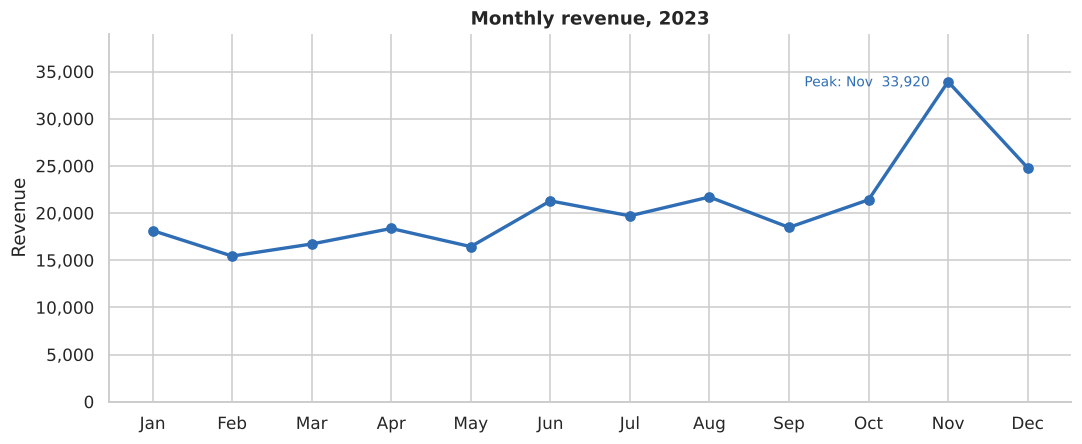

Month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
Revenue,18140.0,15435.0,16715.0,18360.0,16435.0,21285.0,19700.0,21695.0,18475.0,21400.0,33920.0,24790.0
share,7.4,6.3,6.8,7.5,6.7,8.6,8.0,8.8,7.5,8.7,13.8,10.1


In [5]:
monthly = df.groupby("Month")["Total Amount"].sum()
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(monthly.index.astype(str), monthly.values, marker="o", color=BLUE, lw=2.2)
peak = monthly.idxmax()
ax.annotate(f"Peak: {peak.strftime('%b')}  {monthly.max():,.0f}", (str(peak), monthly.max()),
            textcoords="offset points", xytext=(-12, -3), ha="right", fontsize=9, color=BLUE)
ax.set(title="Monthly revenue, 2023", xlabel="", ylabel="Revenue")
ax.yaxis.set_major_formatter(money)
ax.set_xticklabels([p.strftime("%b") for p in monthly.index])
ax.set_ylim(0, monthly.max() * 1.15)
plt.tight_layout(); plt.show()
monthly.to_frame("Revenue").assign(share=lambda d: (d.Revenue / d.Revenue.sum() * 100).round(1)).T

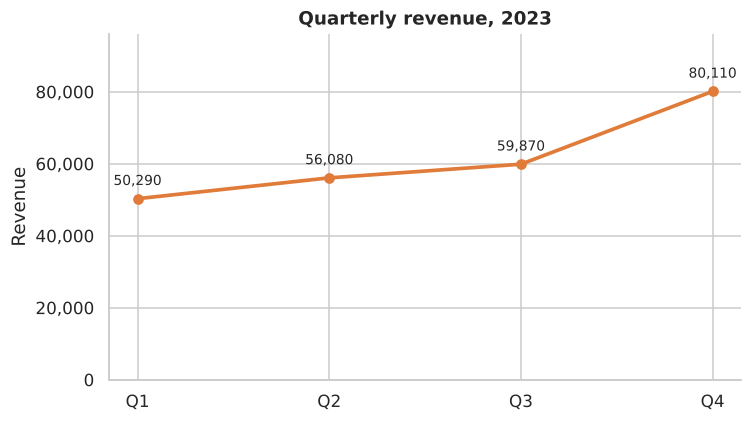

Quarter,2023Q1,2023Q2,2023Q3,2023Q4
Revenue,50290.0,56080.0,59870.0,80110.0
Share %,20.4,22.8,24.3,32.5
QoQ growth %,NaN,11.5,6.8,33.8


In [6]:
quarterly = df.groupby("Quarter")["Total Amount"].sum()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([f"Q{p.quarter}" for p in quarterly.index], quarterly.values, marker="o", color=ORANGE, lw=2.4)
for x, y in zip([f"Q{p.quarter}" for p in quarterly.index], quarterly.values):
    ax.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(title="Quarterly revenue, 2023", xlabel="", ylabel="Revenue")
ax.yaxis.set_major_formatter(money); ax.set_ylim(0, quarterly.max() * 1.2)
plt.tight_layout(); plt.show()
pd.DataFrame({"Revenue": quarterly, "Share %": (quarterly / quarterly.sum() * 100).round(1),
              "QoQ growth %": (quarterly.pct_change() * 100).round(1)}).T

**Observations**
- Revenue is clearly **seasonal and back-loaded**. February is the weakest month (about 15,400) and **November is the strongest by a wide margin** (about 33,900, roughly 14% of the whole year), followed by December (about 24,800).
- Quarterly, revenue climbs every quarter: Q1 about 50,300, Q2 about 56,100, Q3 about 59,900 and **Q4 about 80,100**. Q4 alone is roughly 33% of annual revenue, a jump of about 34% on Q3, while Q1 is the weakest quarter at about 20%.
- Between March and October the line is fairly flat with small ups and downs (June, August and October are mild highs). The real story is the **November-December holiday spike** and the **January-March trough**.

## 4. Customer demographics
Age group and gender breakdown.

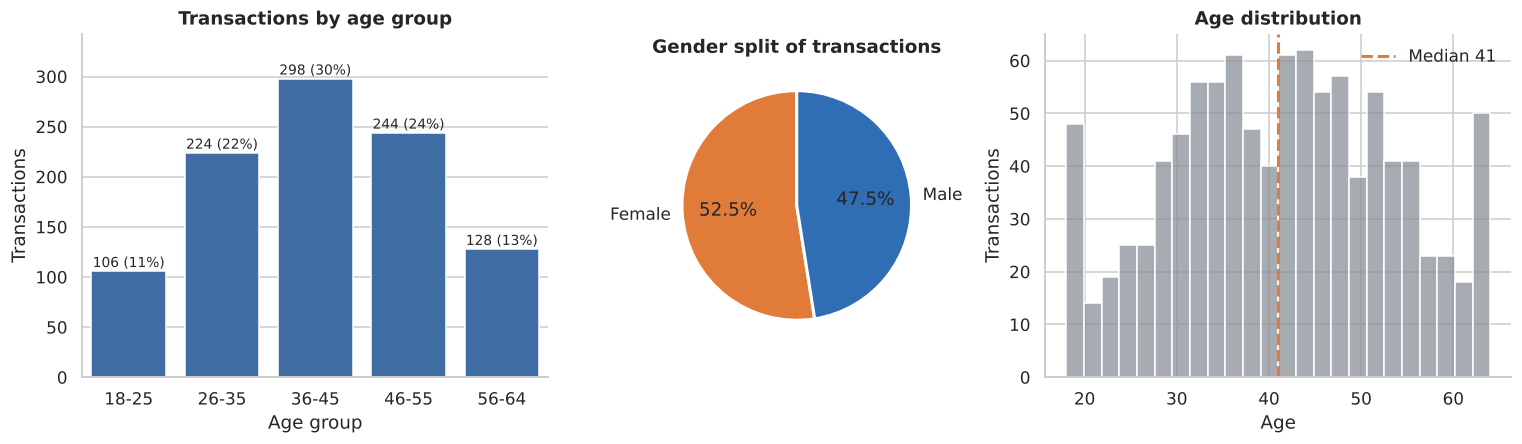

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 0.8, 1.3]})

age_counts = df["Age Group"].value_counts().sort_index()
sns.barplot(x=age_counts.index.astype(str), y=age_counts.values, color=BLUE, ax=axes[0])
for i, v in enumerate(age_counts.values):
    axes[0].text(i, v + 4, f"{v} ({v/len(df):.0%})", ha="center", fontsize=9)
axes[0].set(title="Transactions by age group", xlabel="Age group", ylabel="Transactions")
axes[0].set_ylim(0, age_counts.max() * 1.15)

g = df["Gender"].value_counts()
axes[1].pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90,
            colors=[ORANGE, BLUE], wedgeprops={"edgecolor": "white", "linewidth": 2})
axes[1].set_title("Gender split of transactions")

sns.histplot(df["Age"], bins=24, color=GREY, ax=axes[2])
axes[2].axvline(df["Age"].median(), color=ORANGE, ls="--", lw=2, label=f"Median {df['Age'].median():.0f}")
axes[2].legend(frameon=False)
axes[2].set(title="Age distribution", xlabel="Age", ylabel="Transactions")
plt.tight_layout(); plt.show()

,transactions,revenue,avg_ticket,revenue share %
Gender,,,,
Female,525,119745,228.1,48.6
Male,475,126605,266.5,51.4


,transactions,revenue,avg_ticket,revenue share %
Age Group,,,,
18-25,106,27610,260.5,11.2
26-35,224,54195,241.9,22.0
36-45,298,67675,227.1,27.5
46-55,244,70350,288.3,28.6
56-64,128,26520,207.2,10.8


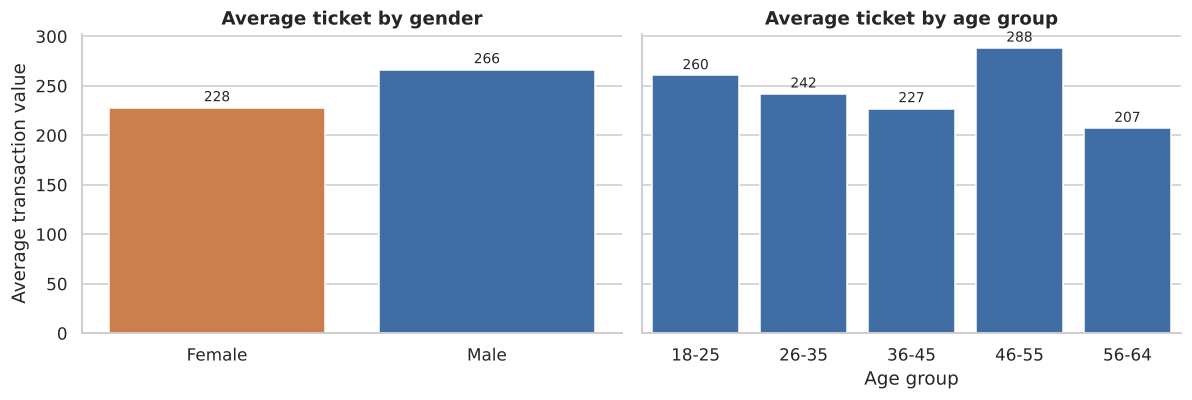

In [8]:
by_gender = df.groupby("Gender")["Total Amount"].agg(transactions="count", revenue="sum", avg_ticket="mean").round(1)
by_gender["revenue share %"] = (by_gender["revenue"] / by_gender["revenue"].sum() * 100).round(1)
by_age = df.groupby("Age Group", observed=True)["Total Amount"].agg(transactions="count", revenue="sum", avg_ticket="mean").round(1)
by_age["revenue share %"] = (by_age["revenue"] / by_age["revenue"].sum() * 100).round(1)
display(by_gender); display(by_age)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
sns.barplot(x=by_gender.index, y=by_gender["avg_ticket"], palette=[ORANGE, BLUE], ax=axes[0])
axes[0].set(title="Average ticket by gender", xlabel="", ylabel="Average transaction value")
sns.barplot(x=by_age.index.astype(str), y=by_age["avg_ticket"], color=BLUE, ax=axes[1])
axes[1].set(title="Average ticket by age group", xlabel="Age group", ylabel="")
for ax in axes:
    for c in ax.containers: ax.bar_label(c, fmt="%.0f", padding=2, fontsize=9)
plt.tight_layout(); plt.show()

**Observations**
- The customer base is **mid-aged**. The **36-45 group is the largest (about 30% of transactions)**, followed by 46-55 (about 24%) and 26-35 (about 22%). The 18-25 group is the smallest at about 11%, with 56-64 at about 13%.
- The small spikes at the youngest and oldest ages in the histogram are an artefact of the 18-64 cap in this file, not real clusters of customers.
- **Gender is close to balanced**, with 52.5% female and 47.5% male transactions.
- Despite being the *minority* of transactions, **men spend more per transaction** (average about 267 against about 228 for women) and so generate **about 51% of revenue**.
- By age, **46-55 has the highest average ticket (about 288)** while 56-64 has the lowest (about 207). Frequency and value do not peak in the same group: 36-45 buys most often but at a lower average value than 46-55.

## 5. Product analysis
Top 10 best-selling products (by units) and revenue by product category.

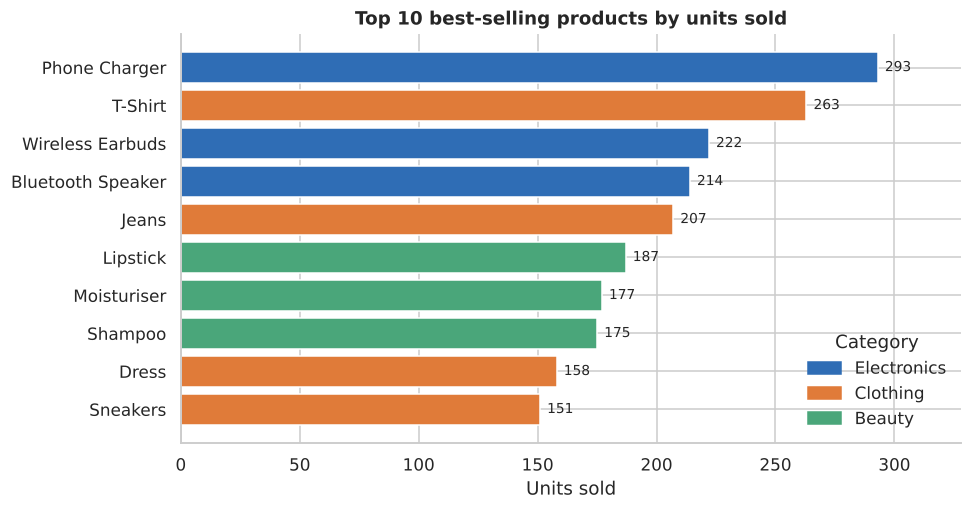

In [9]:
top10 = df.groupby(PRODUCT_COL)["Quantity"].sum().sort_values(ascending=False).head(10)
prod_cat = df.drop_duplicates(PRODUCT_COL).set_index(PRODUCT_COL)["Product Category"]
colors = [CAT_COLORS[prod_cat[p]] for p in top10.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1])
for i, v in enumerate(top10.values[::-1]):
    ax.text(v + 3, i, f"{v:,}", va="center", fontsize=9)
ax.set(title=f"Top 10 best-selling products by units sold", xlabel="Units sold", ylabel="")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_COLORS.values()]
ax.legend(handles, CAT_COLORS.keys(), title="Category", frameon=False, loc="lower right")
ax.set_xlim(0, top10.max() * 1.12)
plt.tight_layout(); plt.show()

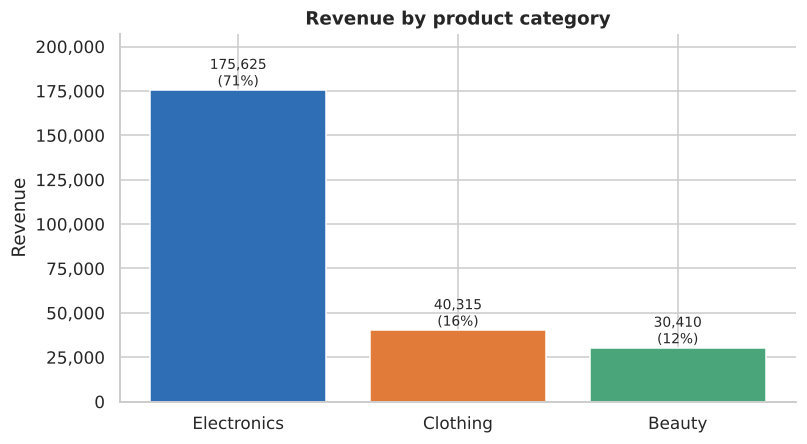

,revenue,transactions,avg_ticket,revenue share %,transaction share %
Product Category,,,,,
Electronics,175625,380,462.2,71.3,38.0
Clothing,40315,342,117.9,16.4,34.2
Beauty,30410,278,109.4,12.3,27.8


In [10]:
cat_rev = df.groupby("Product Category")["Total Amount"].agg(revenue="sum", transactions="count", avg_ticket="mean")
cat_rev["revenue share %"] = (cat_rev["revenue"] / cat_rev["revenue"].sum() * 100).round(1)
cat_rev["transaction share %"] = (cat_rev["transactions"] / cat_rev["transactions"].sum() * 100).round(1)
cat_rev = cat_rev.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bars = ax.bar(cat_rev.index, cat_rev["revenue"], color=[CAT_COLORS[c] for c in cat_rev.index])
for b, share in zip(bars, cat_rev["revenue share %"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2500, f"{b.get_height():,.0f}\n({share:.0f}%)", ha="center", fontsize=9)
ax.set(title="Revenue by product category", xlabel="", ylabel="Revenue")
ax.yaxis.set_major_formatter(money); ax.set_ylim(0, cat_rev["revenue"].max() * 1.18)
plt.tight_layout(); plt.show()
cat_rev.round(1)

**Observations**
- By **units sold**, the top 10 is led by **Phone Charger (293)**, then T-Shirt (263), Wireless Earbuds (222), Bluetooth Speaker (214) and Jeans (207). Best-sellers are mostly **low-priced everyday items**, and all three categories appear in the list.
- By **revenue**, one category dominates: **Electronics earns about 175,600, roughly 71% of total revenue**, against about 40,300 for Clothing (16%) and about 30,400 for Beauty (12%).
- Electronics is only about **38% of transactions** but a far larger share of revenue, because its average ticket (about 462) is roughly four times that of Clothing (about 118) or Beauty (about 109).

## 6. Correlation heatmap
Relationships between the numerical variables.

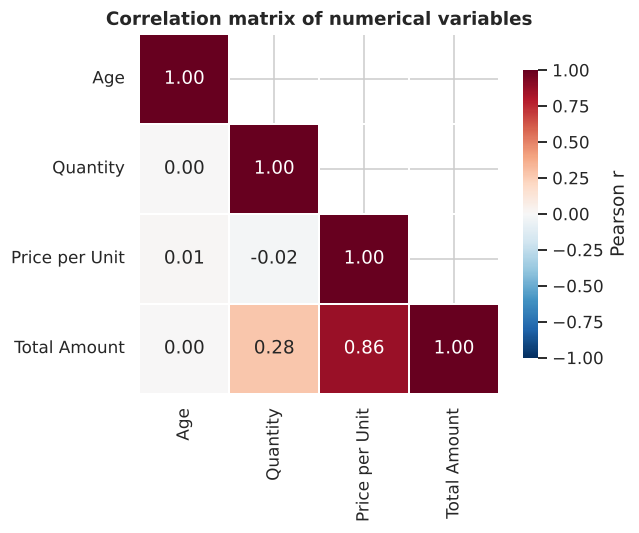

In [11]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", square=True, cbar_kws={"shrink": 0.8, "label": "Pearson r"}, ax=ax)
ax.set_title("Correlation matrix of numerical variables")
plt.tight_layout(); plt.show()

**Observations**
- **Total Amount is driven almost entirely by price per unit (r = 0.86)**, with a weak link to quantity (r = 0.28). Revenue depends on *which* products customers buy far more than on *how many* they buy.
- **Age is essentially uncorrelated with everything** (r close to 0), so age on its own does not predict how much someone spends. Any age effect shows up through *what* they buy (see below), not through basket size.
- Price per unit and quantity are almost unrelated (r about -0.02), so customers do not noticeably buy more of cheaper items.
- Caveat: Pearson correlation only captures linear relationships and is weakened here because price takes just a handful of discrete values.

## 7. Additional visualisation: best-sellers are not the money-makers
Top products ranked by **units** can hide where the money actually comes from. Comparing each product's share of units sold with its share of revenue exposes the gap.

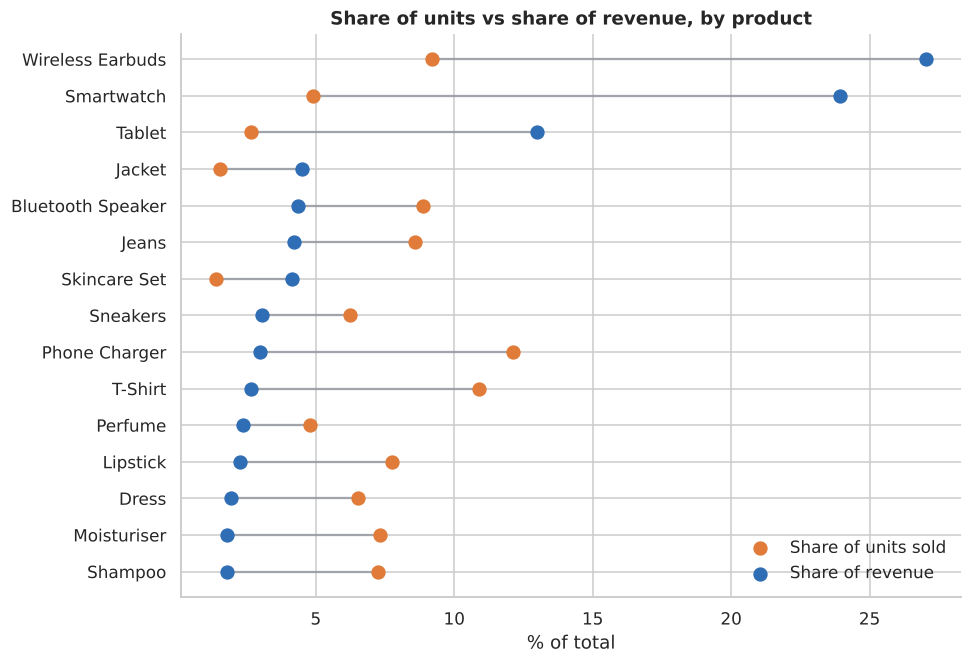

Top 3 products by revenue = 64% of revenue but only 17% of units.


,units,revenue,Share of units %,Share of revenue %
Product Name,,,,
Wireless Earbuds,222,66600,9.2,27.0
Smartwatch,118,59000,4.9,23.9
Tablet,64,32000,2.6,13.0
Jacket,37,11100,1.5,4.5
Bluetooth Speaker,214,10700,8.9,4.3
Jeans,207,10350,8.6,4.2
Skincare Set,34,10200,1.4,4.1
Sneakers,151,7550,6.2,3.1
Phone Charger,293,7325,12.1,3.0


In [12]:
p = df.groupby(PRODUCT_COL).agg(units=("Quantity", "sum"), revenue=("Total Amount", "sum"))
p["Share of units %"] = p["units"] / p["units"].sum() * 100
p["Share of revenue %"] = p["revenue"] / p["revenue"].sum() * 100
p = p.sort_values("Share of revenue %", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6.2))
y = np.arange(len(p))
ax.hlines(y, p["Share of units %"], p["Share of revenue %"], color=GREY, lw=1.5, alpha=0.7)
ax.scatter(p["Share of units %"], y, color=ORANGE, s=70, label="Share of units sold", zorder=3)
ax.scatter(p["Share of revenue %"], y, color=BLUE, s=70, label="Share of revenue", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(p.index)
ax.set(title="Share of units vs share of revenue, by product", xlabel="% of total")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

top_rev = p.sort_values("Share of revenue %", ascending=False)
print(f"Top 3 products by revenue = {top_rev['Share of revenue %'].head(3).sum():.0f}% of revenue "
      f"but only {top_rev['Share of units %'].head(3).sum():.0f}% of units.")
p.sort_values("Share of revenue %", ascending=False).round(1)[["units", "revenue", "Share of units %", "Share of revenue %"]]

**Observations (the non-obvious insight)**
- The **best-seller by units, Phone Charger, ranks only about 9th by revenue (about 3% of revenue)**. In contrast, **Wireless Earbuds (about 27%) and Smartwatch (about 24%) together generate roughly half of all revenue** while representing only a modest slice of units.
- **A volume-based "best-seller" list is misleading for decision-making.** It points to cheap accessories that attract traffic, while the products that actually fund the business are a handful of high-priced electronics.
- This also explains the earlier correlation result: revenue tracks price, so a few expensive SKUs decide the outcome. It makes the business **concentrated and exposed** if those SKUs go out of stock or lose demand.

## 8. Conclusion and recommendations

**Summary of findings (on this dataset)**
1. Sales are strongly seasonal: **Q4 is about a third of annual revenue, with November the peak month**, and Q1 is the weakest quarter.
2. **Electronics is about 71% of revenue from about 38% of transactions**, and two products (Wireless Earbuds, Smartwatch) generate about half of revenue.
3. Customers are mostly 26-55. **Men spend more per transaction** than women (about 267 vs 228), and the **46-55 group has the highest average ticket** while the 18-25 group is the smallest.
4. Revenue is driven by price per unit, not basket size or age.

**Recommendations**
1. **Plan inventory and staffing around the November peak, and use the January-March trough for demand creation.** Build safety stock of high-value electronics before November (the month alone is about 14% of annual revenue, and a stock-out on the top products would be very costly). Then run promotions, loyalty rewards or bundles in Q1, when revenue is about 20% of the year, to smooth the cycle.
2. **Use best-selling cheap accessories as a bridge to high-value products.** Phone Chargers lead on units but contribute only about 3% of revenue. Bundle them (and speakers) with Earbuds or a Smartwatch at the point of sale, and offer a discounted accessory with any high-ticket purchase, to raise the average basket where it matters. Track attach rate as the KPI.
3. **Close the gender spend gap with targeted offers.** Women are 52.5% of transactions but only about 49% of revenue, and their spend skews toward Clothing and Beauty (men put about 80% of spend into Electronics versus about 63% for women). Promote mid-to-high-ticket Electronics and premium Beauty (for example the Skincare Set) to female customers, and test whether gifting-focused messaging in Q4 lifts it.
4. **Grow the 46-55 high-value segment and invest in acquiring 18-25 customers.** The 46-55 group has the highest average ticket (about 288), so premium and warranty-led offers suit them. The 18-25 group is only about 11% of transactions, and over a fifth of its spend goes to Clothing (the highest of any age group), so a Clothing-led, social-first acquisition campaign could build a future customer base.
5. **Reduce concentration risk.** Two SKUs carry about half of revenue, so diversify supply for them and grow the mid-priced range (for example Jackets and Skincare Sets) so a single supplier or demand shock cannot erase half the business.

**Limitations and next steps**
- The data covers one year, so seasonality cannot be separated from a one-off trend; multi-year data would confirm it.
- The file is synthetic, so the specific percentages are illustrative. **Re-run the notebook on a real dataset and re-check each observation before acting on it.**
- Natural extensions: customer-level repeat-purchase analysis (RFM), a statistical test for the gender difference in average ticket (for example a Mann-Whitney U test), and a simple forecasting model for monthly revenue.